In [1]:
from pathlib import Path
import pandas as pd

tf_path = 'data/curate/GE6_txn_processed.parquet'
dbs_path = 'data/curate/daily_balance_sheet.parquet'
dov_path = 'data/persist/daily_overview.parquet'
tvat_path = 'data/curate/top_voters_all_time.parquet'

df_transfers = pd.read_parquet(tf_path)
daily_balance_sheet = pd.read_parquet(dbs_path)
daily_overview = pd.read_parquet(dov_path)
top_voters_all_time = pd.read_parquet(tvat_path)

vote_acc = '0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F'
hof = '0xaB4d90d445d2a875c96831d6c4392aA80150aCEf'
hof_2 = "0xd32308745C5C23dF577197c8f17Dd5b83C495978"
buu = '0x545bdc1851C09c21045d8B2cD3b17545B176E6a8'
hidden_buu = '0x38321F6C8DB96a672C8395AF996f0A97450c96C4'
my_acc = '0xc13e6b44e50091569684226b1dD312A1c749862E'
source = "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255"
mint="0x0000000000000000000000000000000000000000"
m = "0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450"

#official_accs = list(df_transfers.query('From == "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255" and Method == "transfer"')['To'].unique())
official_accs = ['0x4924829CBBFB3B7DE7469098A7867d43a5cd248a',
       '0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
       '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
       '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
       '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
       '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
       '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
       '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
       '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
       '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148']

ex = official_accs + [source, vote_acc,mint]



In [2]:
old_result = pd.read_csv("D:/Users/N678026/Downloads/ge5_stat.xlsx - ge5_spender_v2.csv")

mask_fame = old_result['GE4'].str.contains(r'Fame-', na=False)
mask_monet = old_result['GE4'].str.contains(r'Monet-', na=False)
mask_pancake = old_result['GE5'].str.contains(r'Pancake', na=False)
mask_yoghurt = old_result['GE5'].str.contains(r'Yoghurt', na=False)
mask_hoop = old_result['GE5'].str.contains(r'Hoop', na=False)


old_result.loc[mask_fame, 'Fame_number'] = (
    old_result.loc[mask_fame, 'GE4']
      .str.extract(r'Fame-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

old_result.loc[mask_monet, 'Monet_number'] = (
    old_result.loc[mask_monet, 'GE4']
      .str.extract(r'Monet-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)


old_result.loc[mask_pancake, 'Pancake_number'] = (
    old_result.loc[mask_pancake, 'GE5']
      .str.extract(r'Pancake BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)


old_result.loc[mask_yoghurt, 'Yoghurt_number'] = (
    old_result.loc[mask_yoghurt, 'GE5']
      .str.extract(r'Yoghurt BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

old_result.loc[mask_hoop, 'Hoop_number'] = (
    old_result.loc[mask_hoop, 'GE5']
      .str.extract(r'Hoop BNK48-(\d+(?:\.\d+)?)')[0]
      .astype(float)
)

threshold = 100
fame_voters = list(old_result[old_result['GE4'].str.contains('Fame')].query(f'Fame_number >= {threshold}')['Wallet address'].unique())
monet_voters = list(old_result[old_result['GE4'].str.contains('Monet')].query(f'Monet_number >= {threshold}')['Wallet address'].unique())

pancake_voters = list(old_result[old_result['GE5'].str.contains('Pancake')].query(f'Pancake_number >= {threshold}')['Wallet address'].unique())
yoghurt_voters = list(old_result[old_result['GE5'].str.contains('Yoghurt')].query(f'Yoghurt_number >= {threshold}')['Wallet address'].unique())
hoop_voters = list(old_result[old_result['GE5'].str.contains('Hoop')].query(f'Hoop_number >= {threshold}')['Wallet address'].unique())


In [3]:
official_accs+[mint,source]

['0x4924829CBBFB3B7DE7469098A7867d43a5cd248a',
 '0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
 '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
 '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
 '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
 '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
 '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
 '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
 '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
 '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148',
 '0x0000000000000000000000000000000000000000',
 '0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255']

In [4]:
# network[['From','num_network']].drop_duplicates().sort_values(by='num_network',ascending=False)

In [5]:
df_transfers.loc[df_transfers['From'] == "0x18ddacC06059d802539cA0B52B499c6BD15D152A"]

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
1855,0x7e541f4d6022d20d42a3e8d91992d622647165347a2d...,0x3be4b73e03cb4ac26d05a8fba527732d51c6b24fad18...,2026-11-10 14:26:13+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0x89e68473f6aCBc38d0713FFD4e1b6220F5157588,1.0,1.000000e+18,token_transfer,3,...,0,0,1,0.0,0.0,1.0,0.0,0.0,52.0,13
1901,0x13f98ade44d31f85bca13e63ee58abd9e1aa08af9fd6...,0x84475510a0f158479a1602ae1c478fe83c0db14aab4f...,2026-11-10 14:21:25+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0xcFeb7105C13Cec12EA0223b7911cFee044B56141,1.0,1.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,1.0,0.0,0.0,52.0,13
2001,0xa2af3f0857bf474a9c081a637fed77c22bdb37b97087...,0xa126d57b635af0812809066a7b2d1783d4817bfb7c18...,2026-11-10 14:13:28+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0x087FB87F1646D8d38A65ffb79bAD5efbF74d1F7e,2.0,2.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,2.0,0.0,0.0,52.0,13
2041,0x944c86ae4ca9fa4ca89e3fe7bbac180b9dfdc819654b...,0x7ef5d4a98d65e0517463809bed3e02dbd7400e4a7444...,2026-11-10 14:10:16+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0xcFeb7105C13Cec12EA0223b7911cFee044B56141,2.0,2.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,2.0,0.0,0.0,52.0,13
2054,0x0dda61a35fae1380d140bc5414427a8821f12ed5121a...,0x5419e8ee440b740e369c334124c320e1a74f75f7c59b...,2026-11-10 14:08:52+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0x5768349103479f4388F01678131a25A6d5F4aD0C,2.0,2.000000e+18,token_transfer,2,...,0,0,1,0.0,0.0,2.0,0.0,0.0,52.0,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61045,0x6ac0e92c4941cf3314be0c033941071fb1c69e7aed61...,0x36432846459560bdd3dc812829d9509d2a7611773f73...,2026-09-26 08:49:25+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0xF68407a04c30FAD63748aaeAe5CCEB4dd2F0b5A3,180.0,1.800000e+20,token_transfer,0,...,0,0,1,0.0,0.0,180.0,0.0,0.0,600.0,5
61047,0x2b1fafdf8bacefc7ad352b4a6987c6460727b5de8736...,0x56d48f15ee3cea04a4de35719f7e3b6f90591e22b852...,2026-09-26 08:46:28+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0xd9080BF717434D398E149fe95d343Df38B33D9f4,40.0,4.000000e+19,token_transfer,0,...,0,0,1,0.0,0.0,40.0,0.0,0.0,600.0,5
61048,0xb668dfe40e83da6a38ad5e6ce071e3940e38f0376cbc...,0xd3d705a6dd63879e185ad22517b7d2d1806de708d216...,2026-09-26 08:45:37+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0x58eebAFD699576C5Bb7b695aD1fDb02F0F89A50E,60.0,6.000000e+19,token_transfer,0,...,0,0,1,0.0,0.0,60.0,0.0,0.0,600.0,5
61050,0xf4407ae60435da1942cbf57c27b255336d1030a986e1...,0x71932e1c5d94e0fe25533e0a39084d0519e688c59079...,2026-09-26 08:43:52+00:00,multipleTransfer,0x18ddacC06059d802539cA0B52B499c6BD15D152A,0x91eF5e8A8Ff131CB9Ab9Cb236BE88FF620974583,200.0,2.000000e+20,token_transfer,0,...,0,0,1,0.0,0.0,200.0,0.0,0.0,600.0,5


In [6]:
network = df_transfers.copy()
network.loc[network['From'].isin(official_accs+[mint,source]),'From']='official'
network.loc[network['To'].isin([vote_acc]),'To'] = 'vote'
network = network.groupby(['From','To']).agg(sum_value=('Value','sum')).reset_index()
network['num_upstreams'] = network.groupby('From')['To'].transform('nunique')
network['num_down_streams'] = network.groupby('To')['From'].transform('nunique')
#network = network.loc[~network['From'].isin(['official'])]

recipient_count = network[['From','num_upstreams']].drop_duplicates()
sender_count = network[['To','num_down_streams']].rename(columns={'To':'From'}).drop_duplicates()

matrix = pd.pivot_table(network,index='From',columns='To',values='sum_value').reset_index()
matrix = matrix.merge(recipient_count,on='From',how='left')\
                .merge(sender_count,on='From',how='left')
matrix.sort_values(by='vote',ascending=False)

,From,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0x001C4982E276c07746606efc1FBA393ef550d488,0x001Dd8b5e6F2CE3CB2681D97d968D9F1eD44dEd8,0x002abABB6B6543528f7C83a1E3B8EB802893B022,0x002cc491932DC6D9EBeE03a3a82bf8e4cEB42A70,0x0040eCc2368C75948f9AEEeAcAa8730349D0E4c5,0x004aA5fadc15d660298889E282cA4b8b21548E6a,0x0052b8D43e22199FC44dc9da1bDDB1606d43A04b,0x0058fcB5e9370D81a299D0943BC3c087845b97f5,...,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,0xff70E564fFe61343d12729166C099395321adF32,0xff7334a5821194e21113923acf49DF0C87e8E588,0xffB9aB5676476c5279BB3D72BA8963c450bF940B,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,0xffcAF2dF01B7d035b5bb91eC834e3B9D100759B4,0xffdB6351b3A3e6a47c1829ba4e8d8f1C4eaaDEc1,vote,num_upstreams,num_down_streams
128,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,104875.0,4,4.0
245,0x0CAC2bB76ac49B17ad374E678855837E125026A4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94401.0,1,4.0
1279,0x3b426f905bFAdD954309e551cE426f5D322021ed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,37000.0,11,7.0
207,0x0929A481B10376Ec340BBa2D44655Ad110223E99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27510.0,6,13.0
2929,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22009.0,3,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5416,0xfB01A7AE284C8caEBF83fCfdbAD1abbCD227D0eC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0
5434,0xfFbeaA565DF3D59466D0dA4cd0065c2755ceC1Ad,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0
5441,0xfb903fC9EF526aC9c0C5e939eB6a08B676b315a0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,2.0
5460,0xff5328cf5b54175aE72c63F0A726C32892ADF5Ed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1.0


In [7]:
df_transfers.loc[df_transfers['From'] == "0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367"]['To'].unique()

array(['0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F',
       '0x2a14051C54F10E3c705da85E690760c081c78070',
       '0x8da977Ce60025a8B738EF562cD56a12411E47eF1',
       '0x607bd39Fe2Ce02718c597eD7F7F2c91ad3736f83'], dtype=object)

In [16]:
df_transfers.loc[df_transfers['From'] == m]

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
5460,0xc0f2fddb244d7768771bb40f8ae0a0c2c0d533f913d0...,0x116f2a632c3e8ba628e1b2741ef1ed644bc00543ba4e...,2026-11-10 02:05:46+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,4.0,4.000000e+18,token_transfer,0,...,1,0,0,4.0,0.0,0.0,0.0,4.0,0.0,1
6801,0xb05e24d043672b1e9302eb055efa724cd943c533ef25...,0xc9fd475748f886ef9768def8de8c5a10df9fea318f98...,2026-11-09 12:42:43+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,20.0,0.0,10
6809,0xfbc9d585dd18e88bb4cf517d9de00d2afb39c8235ddb...,0xa72281ee9582862a244cecb5adc51cfa8d4a8df46ba7...,2026-11-09 12:40:46+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,20.0,0.0,10
6815,0x1ebea6cd5190a61468d48ae95632081ccd99e9dfab4f...,0x9981779870413c33d88262c4463a33820861914426b6...,2026-11-09 12:40:01+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1.0,1.000000e+18,token_transfer,0,...,1,0,0,1.0,0.0,0.0,0.0,20.0,0.0,10
6819,0xd6fa64f6b0a8be14c15108d88f5f018cc3ebee15b8d7...,0xb74ce44f6b86bad262b9c95c0f504c0492c45e2f0d79...,2026-11-09 12:39:07+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1.0,1.000000e+18,token_transfer,0,...,1,0,0,1.0,0.0,0.0,0.0,20.0,0.0,10
6820,0x8a969cc05172f675121dc5baedd46d913ed53d11a9cc...,0xaeed10824fdb65072a70a240bfd9e21bd228894ec747...,2026-11-09 12:38:46+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1.0,1.000000e+18,token_transfer,0,...,1,0,0,1.0,0.0,0.0,0.0,20.0,0.0,10
6821,0x46516a44efecef7ba94bbbcc2c469030ca70d9729471...,0x888bca78ce922c923b98ab97c6e800d8735bb889ee39...,2026-11-09 12:38:31+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,20.0,0.0,10
6822,0x1729a741c7946a766c7100ba0749d88f4a9e72cc3674...,0x93f79b9e6a2445090695fb4b4c5aae42edab703096e3...,2026-11-09 12:37:55+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,20.0,0.0,10
7898,0xcb2869086397176c3329a1e0aeb9a8db26eb3c80cbfc...,0xeca5b150f4b9f270ca1017e86417e84a3d395fc26b03...,2026-11-09 03:22:04+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1.0,1.000000e+18,token_transfer,0,...,1,0,0,1.0,0.0,0.0,0.0,20.0,0.0,10
7914,0xdbadf09a28c2bb4db6afee6dce186fd670595e6145f2...,0xd47c79cd06467daf8c57c1afd43d8a0fd6ce9789f595...,2026-11-09 03:15:31+00:00,vote,0x2EAD242f81107Ae9Cb3D02F46CeB5e7923BA1450,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3.0,3.000000e+18,token_transfer,0,...,1,0,0,3.0,0.0,0.0,0.0,20.0,0.0,10


In [9]:
df_transfers.loc[df_transfers['Method'] == 'vote']['Value'].sum()

1056338.5191053988

In [10]:
print(hidden_buu)
df_transfers.loc[df_transfers['To'] == buu][['Datetime','From','To','Method','Value']] #['To'].unique()

0x38321F6C8DB96a672C8395AF996f0A97450c96C4


,Datetime,From,To,Method,Value
1399,2026-11-10 22:00:13+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,3318.4
1934,2026-11-10 21:18:43+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,11.0
2992,2026-11-10 19:47:52+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,96.0
5405,2026-11-10 09:34:19+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,28.0
7063,2026-11-09 18:15:46+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,195.0
7209,2026-11-09 17:12:07+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,100.0
7221,2026-11-09 17:07:16+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,516.0
8178,2026-11-09 02:33:34+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,103.0
8261,2026-11-09 00:47:04+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,100.0
11512,2026-11-07 11:21:31+07:00,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,multipleTransfer,300.0


In [11]:
['Date',
 'wallet_address',
 'accum_in_bound_amount',
 'accum_vote',
 'balance',
 'potential_vote_amount',
 'GE5',
 'GE4',
 'GE3',
 'ranking_by_vote',
 'previous_date_ranking',
 'ranking_by_potential_vote',
 'ranking_change',
]

['Date',
 'wallet_address',
 'accum_in_bound_amount',
 'accum_vote',
 'balance',
 'potential_vote_amount',
 'GE5',
 'GE4',
 'GE3',
 'ranking_by_vote',
 'previous_date_ranking',
 'ranking_by_potential_vote',
 'ranking_change']

In [17]:
date = "2026-11-11"

top_voters_all_time = pd.read_parquet(tvat_path)
export = top_voters_all_time.loc[top_voters_all_time['Date'].astype('str') == date][['Date','From','accum_in_bound_amount','accum_vote','balance','potential_vote_amount','ranking_by_vote','previous_date_ranking','ranking_by_potential_vote']]
export = export.rename(columns={'From':'wallet_address'}).reset_index(drop=True)
export['ranking_change'] = export['previous_date_ranking']-export['ranking_by_vote']
export_cols = ['Date',
 'wallet_address',
 'accum_in_bound_amount',
 'accum_vote',
 'balance',
 'potential_vote_amount',
 'GE5',
 'GE4',
 'GE3',
 'ranking_by_vote',
 'previous_date_ranking',
 'ranking_by_potential_vote',
 'ranking_change',
]
export = export.merge(old_result,left_on='wallet_address',right_on='Wallet address',how='left')
export[export_cols].to_csv(f'{date}.csv',index=False)

In [13]:
export.head()

,Date,wallet_address,accum_in_bound_amount,accum_vote,balance,potential_vote_amount,ranking_by_vote,previous_date_ranking,ranking_by_potential_vote,ranking_change,...,Wallet address,Vote amount,GE5,GE4,GE3,Fame_number,Monet_number,Pancake_number,Yoghurt_number,Hoop_number
0,2026-11-10,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,130852.0,104875.0,22387.0,127262.0,1,1,1,0,...,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,"103,578.00",['Arlee BNK48-8234.0' 'Jew BNK48-16225.0' 'Loo...,['Lookked-20080.45' 'Minmin-47784.55' 'Nenie-1...,['Minmin-11020.19' 'Pampam-6403.41'],NaN,NaN,2000.0,NaN,NaN
1,2026-11-10,0x0CAC2bB76ac49B17ad374E678855837E125026A4,88044.0,88042.0,2.0,88044.0,2,2,2,0,...,0x0CAC2bB76ac49B17ad374E678855837E125026A4,"7,191.00",['Champoo CGM48-1.0' 'Kaning CGM48-1.0' 'Niya ...,[],[],NaN,NaN,1.0,NaN,NaN
2,2026-11-10,0x0929A481B10376Ec340BBa2D44655Ad110223E99,52368.0,27510.0,1040.0,28550.0,3,3,5,0,...,0x0929A481B10376Ec340BBa2D44655Ad110223E99,9.00,['Lingling CGM48-1.0' 'Prae CGM48-8.0'],[],[],NaN,NaN,NaN,NaN,NaN
3,2026-11-10,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,25011.0,22009.0,1.0,22010.0,4,4,8,0,...,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,"15,044.00",['Hoop BNK48-15044.0'],[],[],NaN,NaN,NaN,NaN,15044.0
4,2026-11-10,0x3b426f905bFAdD954309e551cE426f5D322021ed,43522.0,14500.0,11450.0,25950.0,5,5,6,0,...,0x3b426f905bFAdD954309e551cE426f5D322021ed,20.00,['Micha BNK48-20.0'],['Micha-48.0' 'Pim-310.0' 'Sita-1.0'],['Fame-0.3' 'Hoop-2.0' 'Jaa-5.0' 'Music-1.0' '...,NaN,NaN,NaN,NaN,NaN


In [14]:
export.merge(old_result,left_on='wallet_address',right_on='Wallet address',how='left')[['wallet_address','accum_vote',
                                                                                        'GE5',
                                                                                        'GE4',
                                                                                        'GE3',
                                                                                        ]]

KeyError: "['GE5', 'GE4', 'GE3'] not in index"

In [ ]:
'0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367'

False

In [ ]:
df_transfers.loc[df_transfers['From'] == hof_2]

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
17456,0x88d0fa0e2797c063f11c5da420e442fafbc9555ec0dc...,0x2440ee23d7684f1b2bdf7e43d60f21fadd25fbb92f6e...,2026-10-30 03:16:40+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3592.0,3.592000e+21,token_transfer,0,...,1,0,0,3592.0,0.0,0.0,0.0,3592.0,0.0,1
20006,0x85d9b917d8c320c89a50e1fefc26af09efbdb7204967...,0x6a0553bfd85aaeab50653d2b0fa11c0c869114b96bec...,2026-10-28 06:03:22+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,577.0,5.770000e+20,token_transfer,0,...,1,0,0,577.0,0.0,0.0,0.0,577.0,0.0,1
20597,0x56e68e1480e07972606208ac0f6d5df7c3c5f5fc7456...,0x6560d15c1bac6b12908a99c007fb63a20e7ca9a7afa3...,2026-10-27 12:58:31+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
23363,0x43f624d29a2f90e6b429bc9c4554a4085f59c894ef5c...,0x29a78add887ffd9d37e8dd89b7c0853b8a440fa750d8...,2026-10-24 11:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
29877,0x5a2e2af6f49003dc3b22e2c61a5e0969f6c904e69def...,0x5395a75b6ff66f95048151ac181330f11153db9bb368...,2026-10-14 18:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1


In [ ]:
df_transfers.loc[df_transfers['From'] == hidden_buu].query('is_vote == 0')['Value'].sum()

6421.0

In [ ]:
df_transfers.loc[(df_transfers['To'] == buu)
                 & (df_transfers['From']=="0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148")]['Value'].sum()

2480.0

In [ ]:
export.loc[export['wallet_address'].isin([buu,hidden_buu,hof,hof_2])]#.sort_values(by='balance',ascending=False)

,Date,wallet_address,accum_in_bound_amount,accum_vote,balance,potential_vote_amount,ranking_by_vote,previous_date_ranking,ranking_by_potential_vote,ranking_change
7,2026-11-08,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,8698.0,8598.0,100.0,8698.0,8,7,16,-1
16,2026-11-08,0xd32308745C5C23dF577197c8f17Dd5b83C495978,5173.0,5069.0,104.0,5173.0,17,15,42,-2
173,2026-11-08,0xaB4d90d445d2a875c96831d6c4392aA80150aCEf,6090.0,931.0,0.0,931.0,150,143,237,-7
3936,2026-11-08,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,7734.4,3.0,1513.4,1516.4,536,524,169,-12


In [ ]:
from transform import *
from datetime import datetime
from zoneinfo import ZoneInfo

cut_off_1st = datetime.strptime('2026-10-03 12:00:00','%Y-%m-%d %H:%M:%S').replace(tzinfo=ZoneInfo("Asia/Bangkok"))
transfers_1st = df_transfers.loc[df_transfers['Datetime'] <= cut_off_1st]
daily_1st = create_daily_balance_sheet(transfers_1st,OFFICIAL_ACCS,MINT,SOURCE_ACC)
top_voters_1st = create_top_voters_all_time(daily_1st,ex)
top_voters_1st = top_voters_1st.loc[top_voters_1st['Date'].astype('str') == '2026-10-03']



cut_off_2nd = datetime.strptime('2026-10-31 12:00:00','%Y-%m-%d %H:%M:%S').replace(tzinfo=ZoneInfo("Asia/Bangkok"))
transfers_2nd = df_transfers.loc[df_transfers['Datetime'] <= cut_off_2nd]
daily_2nd = create_daily_balance_sheet(transfers_2nd,OFFICIAL_ACCS,MINT,SOURCE_ACC)
top_voters_2nd = create_top_voters_all_time(daily_2nd,ex)
top_voters_2nd = top_voters_2nd.loc[top_voters_2nd['Date'].astype('str') == '2026-10-31']



In [ ]:
result_diff = top_voters_2nd.merge(top_voters_1st,on=['From'],how='left')
result_diff['vote_diff'] = result_diff['accum_vote_x']-result_diff['accum_vote_y']
result_diff['rank_diff'] = result_diff['ranking_by_vote_y']-result_diff['ranking_by_vote_x']
result_diff[['From','accum_vote_x','accum_vote_y','vote_diff','rank_diff']].loc[result_diff['From'].isin([hof,hof_2])]['accum_vote_x'].sum()

6000.0

In [ ]:
top_voters_2nd['accum_vote'].sum()-top_voters_1st['accum_vote'].sum()

288260.32966000005

In [ ]:
top_voters_2nd.sort_values(by=['accum_vote'],ascending=False)[['From','accum_vote','potential_vote_amount']]

,From,accum_vote,potential_vote_amount
145810,0x0CAC2bB76ac49B17ad374E678855837E125026A4,67000.0,75532.0
145811,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,65463.0,66161.0
145812,0x0929A481B10376Ec340BBa2D44655Ad110223E99,18943.0,19110.0
145813,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,15009.0,15010.0
145814,0x3b426f905bFAdD954309e551cE426f5D322021ed,12500.0,12501.0
...,...,...,...
149491,0x1B9c8bAB9a7b59b9c48b91644B6d86969cbC712b,0.0,27.0
149492,0x1B6e691C9A0290a456FA1d11eeB74cf19Cf52371,0.0,0.0
149493,0x060b0076B93F67e97e6f315515A0a5580d3b7403,0.0,13.0
149494,0x05a9c8Cf80935756F04B4cAB18c36F5c1006acAe,0.0,680.0


In [ ]:
daily_balance_sheet.loc[daily_balance_sheet['From'].isin(['0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367'])]

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
364,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-09-26,216.0,17.0,0.0,0.0,216.0,0.0,0.0,17.0,...,0.0,216.0,216.0,0,0,0,0.0,0.0,0.0,0.0
365,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-09-27,12.0,1.0,0.0,0.0,12.0,0.0,0.0,1.0,...,0.0,228.0,12.0,0,0,0,0.0,0.0,0.0,0.0
366,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-09-30,7384.0,1.0,0.0,7384.0,0.0,0.0,1.0,0.0,...,0.0,7612.0,7384.0,0,0,0,0.0,0.0,0.0,0.0
367,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1186.0,6426.0,-1186.0,0,0,0,0.0,0.0,0.0,0.0
368,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-02,5000.0,1.0,0.0,5000.0,0.0,0.0,1.0,0.0,...,12612.0,0.0,-6426.0,0,0,0,0.0,0.0,0.0,0.0
369,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-03,1000.0,1.0,0.0,1000.0,0.0,0.0,1.0,0.0,...,12686.0,926.0,926.0,0,0,0,0.0,0.0,0.0,0.0
370,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-11,13800.0,1.0,0.0,13800.0,0.0,0.0,1.0,0.0,...,26686.0,726.0,-200.0,0,0,0,0.0,0.0,0.0,0.0
371,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-27,40000.0,1.0,0.0,40000.0,0.0,0.0,1.0,0.0,...,66686.0,726.0,0.0,0,0,0,0.0,0.0,0.0,0.0
372,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,66712.0,700.0,-26.0,0,0,0,0.0,0.0,0.0,0.0
373,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,2026-10-29,1000.0,1.0,0.0,1000.0,0.0,0.0,1.0,0.0,...,67714.0,698.0,-2.0,0,0,0,0.0,0.0,0.0,0.0


C:\Users\N678026\AppData\Local\Temp\ipykernel_36332\413141757.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  holders.groupby(['bin_balance'])['bin_accum_vote'].value_counts().unstack()
C:\Users\N678026\AppData\Local\Temp\ipykernel_36332\413141757.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(sum_balance=('balance','sum')).unstack(),cmap='Blues',annot=True,fmt=".2f"))


<Axes: xlabel='None-bin_accum_vote', ylabel='bin_balance'>

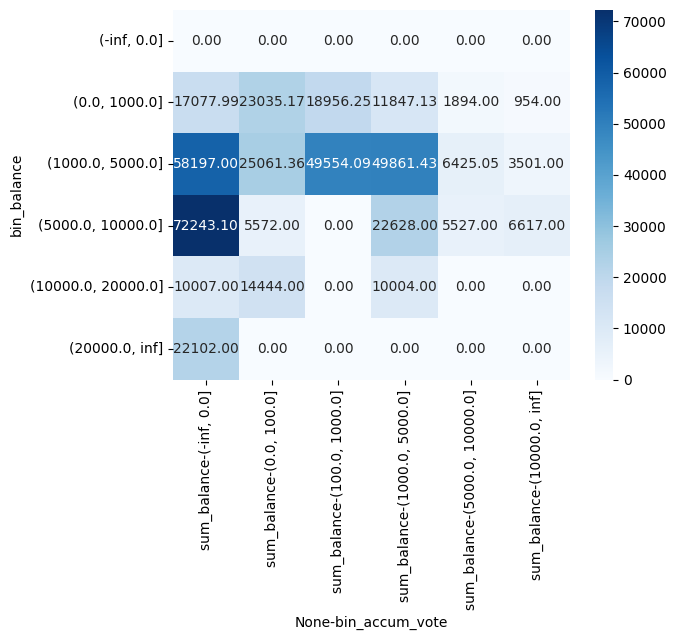

In [ ]:
import seaborn as sns
df= top_voters_all_time
holders = df.loc[df['Date'].astype('str') == date].query('balance > 0').copy()
holders['bin_accum_vote'] = pd.cut(holders['accum_vote'],bins=[-float('inf'),0,100,1000,5000,10000,float('inf')])
holders['bin_balance'] = pd.cut(holders['balance'],bins=[-float('inf'),0,1000,5000,10000,20000,float('inf')],duplicates='drop')
holders.groupby(['bin_balance'])['bin_accum_vote'].value_counts().unstack()
display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(sum_balance=('balance','sum')).unstack(),cmap='Blues',annot=True,fmt=".2f"))


C:\Users\N678026\AppData\Local\Temp\ipykernel_36332\1732233642.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(count=('From','count')).unstack(),cmap='Blues',annot=True,fmt=".0f"))


<Axes: xlabel='None-bin_accum_vote', ylabel='bin_balance'>

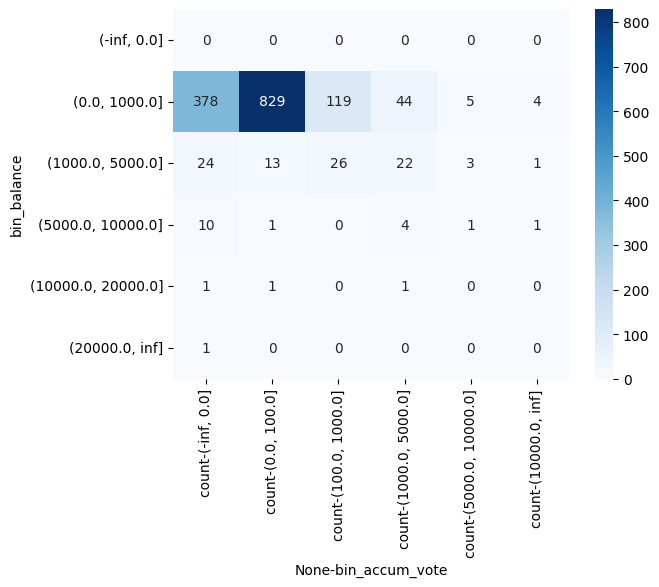

In [ ]:
display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(count=('From','count')).unstack(),cmap='Blues',annot=True,fmt=".0f"))

C:\Users\N678026\AppData\Local\Temp\ipykernel_36332\1249952447.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(sum_vote=('accum_vote','sum')).unstack(),cmap='Blues',annot=True,fmt=".2f"))


<Axes: xlabel='None-bin_accum_vote', ylabel='bin_balance'>

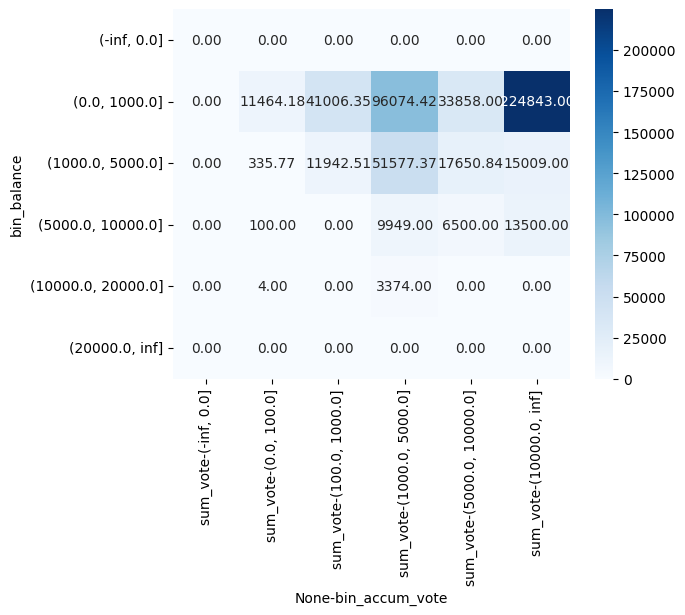

In [ ]:
display(sns.heatmap(holders.groupby(['bin_balance','bin_accum_vote']).agg(sum_vote=('accum_vote','sum')).unstack(),cmap='Blues',annot=True,fmt=".2f"))


In [ ]:
holders['bin_balance'] = pd.qcut(holders['balance'],q=[0, 0.5, 0.9, 0.95, 0.99, 1],
    labels=[
        'Bottom 50%',
        '50–90%',
        '90–95%',
        '95–99%',
        'Top 1%'    
    ])

holders.groupby('bin_balance').agg(sum=('balance','sum'),
                                   max=('balance','max'),
                                   min=('balance','min'),
                                   median=('balance','median'),
                                   wallets=('From','count'))

C:\Users\N678026\AppData\Local\Temp\ipykernel_36332\3600679541.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  holders.groupby('bin_balance').agg(sum=('balance','sum'),


,sum,max,min,median,wallets
bin_balance,,,,,
Bottom 50%,1724.300795,6.9,4.547474e-13,2.0,745
50–90%,42288.240059,556.0,7.000000e+00,20.0,595
90–95%,76060.260000,1500.0,5.580000e+02,1000.0,77
95–99%,179043.673540,5850.0,1.500000e+03,3000.0,57
Top 1%,136392.100000,22102.0,5.904000e+03,7300.0,15


In [ ]:
df = pd.merge(top_voters_all_time.loc[top_voters_all_time['Date'].astype('str') == '2026-10-31'],old_result,left_on='From',right_on='Wallet address',how='left')
df.loc[df['From'].isin(pancake_voters+[buu,hidden_buu])]['potential_vote_amount'].sum()
df.loc[df['From'].isin(pancake_voters)]['potential_vote_amount'].sum()

81652.4

In [ ]:
first_entry = daily_balance_sheet.loc[~daily_balance_sheet['From'].isin(ex)].groupby('From').agg(Date = ('Date','min')).reset_index(drop=False)
first_entry = first_entry.groupby('Date').agg(total_wallets=('From','nunique'))
first_entry['accum_total_wallets'] = first_entry['total_wallets'].cumsum()
first_entry

,total_wallets,accum_total_wallets
Date,,
2026-09-22,1,1
2026-09-26,421,422
2026-09-27,96,518
2026-09-28,57,575
2026-09-29,48,623
2026-09-30,63,686
2026-10-01,749,1435
2026-10-02,321,1756
2026-10-03,309,2065


In [ ]:
daily_balance_sheet.query('From == "0xD9A85E90ab1f93Dd32a94325985E15e7b147c964"')

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
12064,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,2026-09-22,18.0,6.0,0.0,4.0,14.0,0.0,1.0,5.0,...,0.0,18.0,18.0,0,0,0,0.0,0.0,0.0,0.0
12065,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,2026-09-24,9.0,3.0,0.0,0.0,9.0,0.0,0.0,3.0,...,0.0,27.0,9.0,0,0,0,0.0,0.0,0.0,0.0


In [ ]:
df_transfers.loc[df_transfers['Date'].astype('str') == '2026-09-22']

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
54088,0x1effa47c020aabd5d53c127317f32470a5e033a3de53...,0xf248ecf9cd058c574f3c5deec2b7fc340fd22261266f...,2026-09-22 10:49:10+00:00,multipleTransfer,0xd754a0bFF84998306f306DA12a3eEedbDD8abf41,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1
54089,0x207be5a6b2abf3819e2e2c49adea97259e778888c502...,0xcf13ab0aad0e5b5de02b33eca70cf4f8a8cbc560b678...,2026-09-22 10:43:22+00:00,transfer,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,4.0,4.000000e+18,token_transfer,0,...,0,1,0,0.0,4.0,0.0,0.0,0.0,0.0,1
54090,0x8094ab02970dde3dd0fec4c2e5cc3d9a0df6b115cc29...,0x76e653afda167eefa951cdf5443f2642b57b6e37b6a9...,2026-09-22 10:23:40+00:00,multipleTransfer,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,1.0,1.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1.0,1
54091,0x4170cc910f675fd3b0af45f9b9737c005c4ec719736e...,0x9d0d7e7461f9fe8d4046f49192615c9e964ba836615d...,2026-09-22 10:20:46+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,4.0,4.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,4.0,0.0,0.0,4.0,1
54092,0x41c84dbf3d0a80af1900f4238d0b06a910e192c32a53...,0xf3b032438e0c30b48fda0e76f2481a11fbfa16cc9cf2...,2026-09-22 10:10:22+00:00,multipleTransfer,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1
54093,0x54dfa21dc191372fd0d840e0a2d743385eb374dc67b1...,0x427b2af9e2da0b30c1b2b3ee15c1af9865d1910b4273...,2026-09-22 09:49:25+00:00,multipleTransfer,0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB,0xD9A85E90ab1f93Dd32a94325985E15e7b147c964,3.0,3.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,3.0,0.0,0.0,3.0,1


In [ ]:
df_transfers.query(f'From == "0xd32308745C5C23dF577197c8f17Dd5b83C495978"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
17456,0x88d0fa0e2797c063f11c5da420e442fafbc9555ec0dc...,0x2440ee23d7684f1b2bdf7e43d60f21fadd25fbb92f6e...,2026-10-30 03:16:40+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3592.0,3.592000e+21,token_transfer,0,...,1,0,0,3592.0,0.0,0.0,0.0,3592.0,0.0,1
20006,0x85d9b917d8c320c89a50e1fefc26af09efbdb7204967...,0x6a0553bfd85aaeab50653d2b0fa11c0c869114b96bec...,2026-10-28 06:03:22+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,577.0,5.770000e+20,token_transfer,0,...,1,0,0,577.0,0.0,0.0,0.0,577.0,0.0,1
20597,0x56e68e1480e07972606208ac0f6d5df7c3c5f5fc7456...,0x6560d15c1bac6b12908a99c007fb63a20e7ca9a7afa3...,2026-10-27 12:58:31+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
23363,0x43f624d29a2f90e6b429bc9c4554a4085f59c894ef5c...,0x29a78add887ffd9d37e8dd89b7c0853b8a440fa750d8...,2026-10-24 11:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
29877,0x5a2e2af6f49003dc3b22e2c61a5e0969f6c904e69def...,0x5395a75b6ff66f95048151ac181330f11153db9bb368...,2026-10-14 18:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1


In [ ]:
top_voters_all_time.loc[top_voters_all_time['From'].isin([hof,buu,hidden_buu,hof_2])].head(4)

,Date,From,out_bound_vote_amount,accum_in_bound_amount,accum_out_bound_amount,balance,accum_vote,potential_vote_amount,ranking_by_vote,ranking_by_potential_vote,previous_date_ranking
7,2026-11-09,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,303.0,8901.0,8901.0,0.0,8901.0,8901.0,8,16,8
16,2026-11-09,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0.0,5173.0,5069.0,104.0,5069.0,5173.0,17,42,17
174,2026-11-09,0xaB4d90d445d2a875c96831d6c4392aA80150aCEf,0.0,6090.0,6090.0,0.0,931.0,931.0,151,239,150
3804,2026-11-09,0x38321F6C8DB96a672C8395AF996f0A97450c96C4,0.0,7734.4,6424.0,1310.4,3.0,1313.4,538,189,536


In [ ]:
top_voters_all_time['From'].nunique()

5258

In [ ]:
top_voters_all_time.query('accum_vote == 0 and balance > 0').groupby('Date').agg(balance=('balance','sum'),
                                                                 wallets=('From','nunique'))

,balance,wallets
Date,,
2026-09-22,18.00,1
2026-09-27,86435.00,486
2026-09-28,112535.00,538
2026-09-29,128183.00,576
2026-09-30,165223.00,636
2026-10-01,107295.00,280
2026-10-02,94049.00,243
2026-10-03,76688.00,261
2026-10-04,75663.50,293


In [ ]:
first_vote_date = df_transfers.query('Method == "vote"').groupby('From').agg(Date = ('Date','min')).reset_index()
first_vote_date = first_vote_date.groupby('Date').agg(new_voters=('From','count'))
first_vote_date['accum_voter'] = first_vote_date['new_voters'].cumsum()
voter_overview = first_vote_date.merge(first_entry,on=['Date'],how='left')[['accum_total_wallets','accum_voter']]
voter_overview['accum_no_vote'] = voter_overview['accum_total_wallets'] - voter_overview['accum_voter']
voter_overview

,accum_total_wallets,accum_voter,accum_no_vote
Date,,,
2026-10-01,1435,1109,326
2026-10-02,1756,1461,295
2026-10-03,2065,1752,313
2026-10-04,2222,1870,352
2026-10-05,2287,1921,366
2026-10-06,2352,1983,369
2026-10-07,2428,2052,376
2026-10-08,2533,2158,375
2026-10-09,2634,2245,389


In [ ]:
daily_balance_sheet.query('balance > 0').groupby('Date').agg(num_holders = ('From','count'))

,num_holders
Date,
2026-09-07,1
2026-09-21,10
2026-09-22,7
2026-09-24,3
2026-09-26,411
2026-09-27,140
2026-09-28,102
2026-09-29,95
2026-09-30,118


In [ ]:
latest_summary = daily_balance_sheet.drop_duplicates(subset=['From'],keep='last').copy()
latest_summary.query('balance > 0')  #.groupby('Date').agg(num_holders = ('From','count'))

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
14,0x002abABB6B6543528f7C83a1E3B8EB802893B022,2026-11-05,400.0,1.0,0.0,0.0,400.0,0.0,0.0,1.0,...,460.0,549.0,400.0,0,0,0,0.0,0.0,0.0,0.0
24,0x004aA5fadc15d660298889E282cA4b8b21548E6a,2026-10-29,594.0,3.0,0.0,0.0,594.0,0.0,0.0,3.0,...,0.0,2772.0,594.0,0,0,0,0.0,0.0,0.0,0.0
28,0x0052b8D43e22199FC44dc9da1bDDB1606d43A04b,2026-11-04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,9.0,3.0,-3.0,0,0,0,0.0,0.0,0.0,0.0
31,0x0058fcB5e9370D81a299D0943BC3c087845b97f5,2026-11-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,30.0,15.0,-30.0,0,0,0,0.0,0.0,0.0,0.0
36,0x007aC76feCC838D89d19b75d99109D06Bf8c6f57,2026-10-26,12.0,1.0,0.0,0.0,12.0,0.0,0.0,1.0,...,10.0,2.0,2.0,0,0,0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16472,0xfe0F56dd0BB2393F294015482175f212DE230343,2026-11-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,14.0,23.0,-7.0,0,0,0,0.0,0.0,0.0,0.0
16474,0xfe483E515b99ba89dEa7ed2b78faA04f59fC5C60,2026-10-14,4.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,...,2.0,2.0,2.0,0,0,0,0.0,0.0,0.0,0.0
16482,0xff351Ac303fd78DCA5473d78d215FCE22575ae6a,2026-10-15,7.0,1.0,0.0,0.0,7.0,0.0,0.0,1.0,...,0.0,7.0,7.0,0,0,0,0.0,0.0,0.0,0.0
16490,0xff3ff801F91C673c11099E14e40D59D30c4682eF,2026-11-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,7.0,2.0,-1.0,0,0,0,0.0,0.0,0.0,0.0


In [ ]:
df_transfers.query('Method == "vote"')['From'].nunique()

4709

In [ ]:
df_transfers.query('Method == "vote"').groupby('Date').agg(vote_amount= ('Value','sum'),
                                                           voters = ('From','nunique'))#['vote_amount']#.sum()

,vote_amount,voters
Date,,
2026-10-01,69979.286163,1109
2026-10-02,55218.578800,546
2026-10-03,60751.673500,528
2026-10-04,6574.600000,231
2026-10-05,1257.300000,116
2026-10-06,20753.210000,124
2026-10-07,6365.386700,133
2026-10-08,4133.950000,232
2026-10-09,4428.390000,196


In [ ]:
from datetime import datetime
vote_begins = datetime.fromisoformat('2026-10-01')
first_vote_date = df_transfers.loc[(df_transfers['in_game'] == 1)
                                   & (pd.to_datetime(df_transfers['Date']) >= vote_begins)].groupby('From').agg(first_vote_date=('Date','min'),
                                                                                                            ).reset_index()
first_vote_date.groupby('first_vote_date').agg(new_voters = ('From','nunique')).sort_values(by='first_vote_date')

,new_voters
first_vote_date,
2026-10-01,1125
2026-10-02,352
2026-10-03,289
2026-10-04,119
2026-10-05,54
2026-10-06,62
2026-10-07,70
2026-10-08,105
2026-10-09,88


In [ ]:
first_entry = daily_balance_sheet.loc[~daily_balance_sheet['From'].isin(ex)].groupby('From').agg(first_date = ('Date','min')).reset_index(drop=False)
wallet_growth = first_entry.groupby('first_date').agg(entry_by_date = ('From','nunique')).sort_values(by='first_date')
wallet_growth['accum_wallet'] = wallet_growth['entry_by_date'].cumsum()
wallet_growth

,entry_by_date,accum_wallet
first_date,,
2026-09-22,1,1
2026-09-26,421,422
2026-09-27,96,518
2026-09-28,57,575
2026-09-29,48,623
2026-09-30,63,686
2026-10-01,749,1435
2026-10-02,321,1756
2026-10-03,309,2065


In [ ]:
hof_2 = "0xd32308745C5C23dF577197c8f17Dd5b83C495978"
df_transfers.query(f'From == "{hof_2}"')
#latest_summary.query(f'From == "{hof_2}"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
17456,0x88d0fa0e2797c063f11c5da420e442fafbc9555ec0dc...,0x2440ee23d7684f1b2bdf7e43d60f21fadd25fbb92f6e...,2026-10-30 03:16:40+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,3592.0,3.592000e+21,token_transfer,0,...,1,0,0,3592.0,0.0,0.0,0.0,3592.0,0.0,1
20006,0x85d9b917d8c320c89a50e1fefc26af09efbdb7204967...,0x6a0553bfd85aaeab50653d2b0fa11c0c869114b96bec...,2026-10-28 06:03:22+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,577.0,5.770000e+20,token_transfer,0,...,1,0,0,577.0,0.0,0.0,0.0,577.0,0.0,1
20597,0x56e68e1480e07972606208ac0f6d5df7c3c5f5fc7456...,0x6560d15c1bac6b12908a99c007fb63a20e7ca9a7afa3...,2026-10-27 12:58:31+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
23363,0x43f624d29a2f90e6b429bc9c4554a4085f59c894ef5c...,0x29a78add887ffd9d37e8dd89b7c0853b8a440fa750d8...,2026-10-24 11:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1
29877,0x5a2e2af6f49003dc3b22e2c61a5e0969f6c904e69def...,0x5395a75b6ff66f95048151ac181330f11153db9bb368...,2026-10-14 18:58:13+00:00,vote,0xd32308745C5C23dF577197c8f17Dd5b83C495978,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,300.0,3.000000e+20,token_transfer,0,...,1,0,0,300.0,0.0,0.0,0.0,300.0,0.0,1


In [ ]:
# import requests
# import pandas as pd
# import time

# try:
#     base_api_url = 'https://scan.tokenx.finance/api/v2/tokens/0x2f5c60bdE7A5ebD2b116BB03cB5232fA1Ea55F1C/holders'

#     headers = {
#         'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36',
#         'Accept': 'application/json'
#     }

#     all_holders = []
#     params = {}
#     page_count = 1

#     print("Starting scraping of all pages...")

#     while True:
#         print(f"Fetching page {page_count}...")
#         response = requests.get(base_api_url, headers=headers, params=params)
#         response.raise_for_status()
#         data = response.json()

#         items = data.get('items', [])
#         if not items:
#             break

#         # Extract decimals and total supply metadata from the first page
#         if page_count == 1:
#             token_info = items[0].get('token', {})
#             decimals = int(token_info.get('decimals', 18))
#             total_supply = float(token_info.get('total_supply', 0))
#             token_name = token_info.get('name')
#             token_symbol = token_info.get('symbol')

#         for item in items:
#             address_info = item.get('address', {})
#             raw_value = float(item.get('value', 0))
#             formatted_value = raw_value / (10 ** decimals)
#             share_pct = (raw_value / total_supply) * 100 if total_supply > 0 else 0.0

#             all_holders.append({
#                 'Address': address_info.get('hash'),
#                 'Balance': formatted_value,
#                 'Share %': f"{share_pct:.6f}%",
#                 'Raw Value': raw_value
#             })

#         # Handle pagination using next_page_params
#         next_page_params = data.get('next_page_params')
#         if next_page_params:
#             params = next_page_params
#             page_count += 1
#             time.sleep(0.5)  # Respectful delay between requests
#         else:
#             break

#     df_holders = pd.DataFrame(all_holders).drop_duplicates()
#     print(f"\nCompleted! Successfully scraped {page_count} pages.")
#     print(f"Token: {token_name} ({token_symbol})")
#     print(f"Total Unique Holders Scraped: {len(df_holders)}")
#     print(f"Total Calculated Supply: {df_holders['Balance'].sum():,.4f} (Expected: {total_supply / (10**decimals):,.4f})")

#     # Display top 15 results
#     display(df_holders.head(15))
# except Exception as e:
#     print(f"An error occurred during scraping: {e}")

In [ ]:
df_transfers.loc[(df_transfers["From"].isin([source]))
                                             &(~df_transfers["To"].isin(official_accs))
].groupby('Date')['Value'].sum()

Date
2026-10-15    7841.0
2026-10-27     119.0
2026-11-02    2166.0
Name: Value, dtype: float64

In [ ]:
daily_balance_sheet['is_official'] = daily_balance_sheet['From'].isin(official_accs).astype('int')
daily_balance_sheet['is_mint'] = daily_balance_sheet['From'].isin([mint]).astype('int')
daily_balance_sheet['is_intermediate'] = daily_balance_sheet['From'].isin([source]).astype('int')

daily_balance_sheet['in_bound_official'] = (daily_balance_sheet['is_official'] * daily_balance_sheet['in_bound_amount'])

daily_balance_sheet['sold_by_official'] = (daily_balance_sheet['out_bound_amount']
                                                                                   * daily_balance_sheet['is_official'])

daily_balance_sheet['sold_by_intermediate'] = (daily_balance_sheet['out_bound_amount']
                                                                                   * daily_balance_sheet['is_intermediate']) - daily_balance_sheet['in_bound_official']

daily_balance_sheet['total_sold'] = daily_balance_sheet['sold_by_official']+daily_balance_sheet['sold_by_intermediate']


daily_sold = daily_balance_sheet.groupby('Date').agg(total_sold=('total_sold','sum')).reset_index().sort_values(by='Date')
daily_sold['accum_sold'] = daily_sold['total_sold'].cumsum()


daily_vote = daily_balance_sheet.groupby('Date').agg(total_vote = ('out_bound_vote_amount','sum')).reset_index().sort_values(by='Date')
daily_vote['accum_vote'] = daily_vote['total_vote'].cumsum()


daily_overview = daily_sold.merge(daily_vote,on='Date',how='outer')
daily_overview['remaining_balance'] = daily_overview['accum_sold'] - daily_overview['accum_vote']
daily_overview[['Date','accum_sold','accum_vote','remaining_balance']].sort_values(by=['Date'],ascending=False)

,Date,accum_sold,accum_vote,remaining_balance
48,2026-11-09,1227573.0,790432.265606,437140.734394
47,2026-11-08,1223005.0,787496.425606,435508.574394
46,2026-11-07,1109290.0,705133.691606,404156.308394
45,2026-11-06,1042356.0,634458.664235,407897.335765
44,2026-11-05,972086.0,597029.107575,375056.892425
43,2026-11-04,915569.0,566040.973135,349528.026865
42,2026-11-03,870151.0,540750.034335,329400.965665
41,2026-11-02,819328.0,512905.493224,306422.506776
40,2026-11-01,787251.0,491258.323224,295992.676776
39,2026-10-31,753815.0,477236.651624,276578.348376


In [ ]:
df_transfers.query(f'From == "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255"')["Method"].unique()

array(['multipleTransfer', 'transfer'], dtype=object)

In [ ]:
df_transfers.loc[df_transfers['Date'].astype(str) <= "2026-10-14"].query(f'From == "{source}"')['To'].unique()

array(['0x4924829CBBFB3B7DE7469098A7867d43a5cd248a',
       '0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
       '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
       '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
       '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
       '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
       '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
       '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
       '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
       '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148'], dtype=object)

In [ ]:
df_transfers.query(f'From == "0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255" and Method == "transfer"')['To'].unique()

array(['0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
       '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
       '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
       '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
       '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
       '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
       '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
       '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
       '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148'], dtype=object)

In [ ]:
daily_balance_sheet['out_bound_vote_amount'].sum()

790432.2656059869

In [ ]:
daily_balance_sheet['out_bound_vote_amount'].sum()

790432.2656059869

In [ ]:
df_transfers.loc[df_transfers['Method'] == 'vote']['Value'].sum()

790432.2656059869

In [ ]:
df_transfers.head()

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
0,0xa6286210d511b097339d14c462ea5f8066463002aa61...,0xb739cfcc27a688387dea447e52b8b8274eabdbf7b231...,2026-11-08 22:31:07+00:00,vote,0x518f310E509b7824779377D690e99f6ddBB463D0,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,0.1,1.000000e+17,token_transfer,0,...,1,0,0,0.1,0.0,0.0,0.0,1.9,0.0,19
1,0x14bfcee7c2b8b3068bd367075c44f177ae042343dbfc...,0x77d121b4ae5f16059eacf14033fabde5b14e3de236ea...,2026-11-08 22:30:31+00:00,vote,0x518f310E509b7824779377D690e99f6ddBB463D0,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,0.1,1.000000e+17,token_transfer,0,...,1,0,0,0.1,0.0,0.0,0.0,1.9,0.0,19
2,0x629cc028fef52d45083377d73dc70a4eb931710d6ee8...,0x8390ae6bfdebdce513bb6a2283dabd30868ebca09263...,2026-11-08 22:10:55+00:00,transfer,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,0xc0C3Bb75706e4b67fD809CabBB9bcfE90EB2BDa7,120.0,1.200000e+20,token_transfer,0,...,0,1,0,0.0,120.0,0.0,0.0,0.0,0.0,14
3,0x4d8723cf565ea5965d29b68c197ec043e9514c574395...,0xb8f1be7eec27a3a113f9e0054a4a2fa08c5e7526f831...,2026-11-08 22:09:13+00:00,vote,0x518f310E509b7824779377D690e99f6ddBB463D0,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,0.1,1.000000e+17,token_transfer,0,...,1,0,0,0.1,0.0,0.0,0.0,1.9,0.0,19
4,0xa5b045a5db667399fd3c111662b7b8f8603b65bbc761...,0xb62d2db10e9e502b25bd4a32ac32997803e28ec8a76d...,2026-11-08 22:07:58+00:00,vote,0x518f310E509b7824779377D690e99f6ddBB463D0,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,0.1,1.000000e+17,token_transfer,3,...,1,0,0,0.1,0.0,0.0,0.0,1.9,0.0,19


In [ ]:
daily_balance_sheet.head()

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
0,0x0000000000000000000000000000000000000000,2026-09-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5000027.0,-5000027.0,-5000027.0,0,1,0,0.0,0.0,0.0,0.0
1,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,2026-10-11,6.0,2.0,0.0,0.0,6.0,0.0,0.0,2.0,...,0.0,6.0,6.0,0,0,0,0.0,0.0,0.0,0.0
2,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,2026-10-15,7.0,1.0,0.0,0.0,7.0,0.0,0.0,1.0,...,6.0,7.0,1.0,0,0,0,0.0,0.0,0.0,0.0
3,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,2026-10-19,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,12.0,1.0,-6.0,0,0,0,0.0,0.0,0.0,0.0
4,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,2026-10-23,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,13.0,0.0,-1.0,0,0,0,0.0,0.0,0.0,0.0


# Prep daily top voter

In [ ]:
top_voters_by_date = daily_balance_sheet.sort_values(by=['Date','out_bound_vote_amount'],ascending=[False,False])[['Date','From','out_bound_vote_amount']].copy()
top_voters_by_date['ranking'] = top_voters_by_date.groupby('Date')['out_bound_vote_amount'].rank(method='dense',ascending=False).astype(int) 
top_voters_by_date#.loc[(top_voters_by_date['ranking'] <= 20) & (top_voters_by_date['out_bound_vote_amount'] > 0)].set_index('Date')[['ranking','From','out_bound_vote_amount']]

,Date,From,out_bound_vote_amount,ranking
14510,2026-11-09,0xc40E365f487dE57d0785994c0E3e192Db3604eEE,900.00,1
13645,2026-11-09,0xa94Cd24D3E7c68A2CE2716253d5A9395752575F8,365.00,2
4352,2026-11-09,0x4523Ea42f01b51C5B77fFA8304D8e6CD9204D0C5,326.04,3
5302,2026-11-09,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,303.00,4
12648,2026-11-09,0xEE0738B4a2b8808b1B760B002Bd6b9A29eb37D54,250.00,5
...,...,...,...,...
13530,2026-09-21,0xa66e830BC83c98A78AC20D1b705E8abE1C768195,0.00,1
15172,2026-09-21,0xd754a0bFF84998306f306DA12a3eEedbDD8abf41,0.00,1
16080,2026-09-21,0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB,0.00,1
0,2026-09-07,0x0000000000000000000000000000000000000000,0.00,1


# Prep top all time voter

In [ ]:
ex = ['0x4924829CBBFB3B7DE7469098A7867d43a5cd248a',
 '0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
 '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
 '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
 '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
 '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
 '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
 '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
 '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
 '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148',
 '0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255',
 '0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F',
 '0x0000000000000000000000000000000000000000']

date_df = pd.DataFrame(daily_balance_sheet['Date'].unique().tolist(),columns=['Date'])
wallet_df = daily_balance_sheet.loc[~daily_balance_sheet['From'].isin(ex)]['From'].drop_duplicates()
top_voters_all_time = date_df.merge(wallet_df,how='cross')
top_voters_all_time = top_voters_all_time.sort_values(by=['From','Date']).merge(daily_balance_sheet[['Date','From','out_bound_vote_amount','accum_in_bound_amount','accum_out_bound_amount','balance']],on=['Date','From'],how='left')
top_voters_all_time['out_bound_vote_amount'] = top_voters_all_time['out_bound_vote_amount'].fillna(0)

cols_to_ffill = [
    'accum_in_bound_amount',
    'accum_out_bound_amount',
    'balance'
]

top_voters_all_time[cols_to_ffill] = (
    top_voters_all_time
    .groupby('From')[cols_to_ffill]
    .ffill().fillna(0)
)

top_voters_all_time = top_voters_all_time.sort_values(by='Date')

top_voters_all_time['accum_vote'] = top_voters_all_time.groupby('From')['out_bound_vote_amount'].transform('cumsum')
top_voters_all_time['potential_vote_amount'] = top_voters_all_time['balance']+top_voters_all_time['accum_vote']
top_voters_all_time = top_voters_all_time.sort_values(by=['Date','accum_vote'],ascending=[True,False])
top_voters_all_time['ranking_by_vote'] = top_voters_all_time.groupby('Date')['accum_vote'].rank(method='dense',ascending=False).astype(int)
top_voters_all_time['ranking_by_potential_vote'] = top_voters_all_time.groupby('Date')['potential_vote_amount'].rank(method='dense',ascending=False).astype(int)
previous_date_ranking_by_vote = top_voters_all_time[['Date','From','ranking_by_vote']].copy().rename(columns={'ranking_by_vote':'previous_date_raking',
                                                                                            })
previous_date_ranking_by_vote['Date'] = previous_date_ranking_by_vote['Date'] + pd.Timedelta(days=1)

top_voters_all_time = top_voters_all_time.merge(previous_date_ranking_by_vote,on = ['Date','From'])


#top_voters_all_time.sort_values(by=['Date','balance'],ascending=[False,False])

top_voters_all_time.sort_values(by=['Date','ranking_by_vote'],ascending=[False,True])

,Date,From,out_bound_vote_amount,accum_in_bound_amount,accum_out_bound_amount,balance,accum_vote,potential_vote_amount,ranking_by_vote,ranking_by_potential_vote,previous_date_raking
231352,2026-11-09,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0.0,106352.0,105664.0,688.0,102698.0,103386.0,1,1,1
231353,2026-11-09,0x0CAC2bB76ac49B17ad374E678855837E125026A4,0.0,88044.0,88001.0,43.0,88001.0,88044.0,2,2,2
231354,2026-11-09,0x0929A481B10376Ec340BBa2D44655Ad110223E99,0.0,46500.0,46328.0,172.0,22510.0,22682.0,3,3,3
231355,2026-11-09,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,0.0,20011.0,16510.0,3501.0,15009.0,18510.0,4,6,4
231356,2026-11-09,0x3b426f905bFAdD954309e551cE426f5D322021ed,0.0,34517.0,27900.0,6617.0,13500.0,20117.0,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...
5253,2026-09-22,0x292f2697217adF4B96322a7475267B07469Ad21f,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5254,2026-09-22,0x9061445377769F417A74925a978E1979959591C7,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5255,2026-09-22,0xC42EF294d8C7e4bd00142B47F7df1b6955ffF61d,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5256,2026-09-22,0xd53395e6e2ED3dDC7683f304a9AF42A5Ccec43F1,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1


In [ ]:
top_voters_all_time.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 236610 entries, 0 to 236609
Data columns (total 11 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   Date                       236610 non-null  object 
 1   From                       236610 non-null  object 
 2   out_bound_vote_amount      236610 non-null  float64
 3   accum_in_bound_amount      236610 non-null  float64
 4   accum_out_bound_amount     236610 non-null  float64
 5   balance                    236610 non-null  float64
 6   accum_vote                 236610 non-null  float64
 7   potential_vote_amount      236610 non-null  float64
 8   ranking_by_vote            236610 non-null  int32  
 9   ranking_by_potential_vote  236610 non-null  int32  
 10  previous_date_raking       236610 non-null  int32  
dtypes: float64(6), int32(3), object(2)
memory usage: 17.1+ MB


In [ ]:
top_voters_all_time.sort_values(by=['From','Date'])

,Date,From,out_bound_vote_amount,accum_in_bound_amount,accum_out_bound_amount,balance,accum_vote,potential_vote_amount,ranking_by_vote,ranking_by_potential_vote,previous_date_raking
4337,2026-09-22,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
9527,2026-09-27,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,0.0,0.0,0.0,0.0,0.0,1,147,1
10885,2026-09-28,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,0.0,0.0,0.0,0.0,0.0,1,168,1
20887,2026-09-29,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,0.0,0.0,0.0,0.0,0.0,1,175,1
25097,2026-09-30,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,0.0,0.0,0.0,0.0,0.0,1,183,1
...,...,...,...,...,...,...,...,...,...,...,...
212187,2026-11-05,0xffdB6351b3A3e6a47c1829ba4e8d8f1C4eaaDEc1,0.0,7.0,7.0,0.0,7.0,7.0,452,518,430
217613,2026-11-06,0xffdB6351b3A3e6a47c1829ba4e8d8f1C4eaaDEc1,0.0,7.0,7.0,0.0,7.0,7.0,461,535,452
222789,2026-11-07,0xffdB6351b3A3e6a47c1829ba4e8d8f1C4eaaDEc1,0.0,7.0,7.0,0.0,7.0,7.0,491,550,461
228262,2026-11-08,0xffdB6351b3A3e6a47c1829ba4e8d8f1C4eaaDEc1,0.0,7.0,7.0,0.0,7.0,7.0,504,570,491


In [ ]:

daily_balance_sheet[['Date','From','out_bound_vote_amount','balance']]

,Date,From,out_bound_vote_amount,balance
0,2026-09-07,0x0000000000000000000000000000000000000000,0.0,-5000027.0
1,2026-10-11,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,0.0,6.0
2,2026-10-15,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,6.0,7.0
3,2026-10-19,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,5.0,1.0
4,2026-10-23,0x000A56f2615d37ef7da3c68E2Be55670d3E25330,1.0,0.0
...,...,...,...,...
16517,2026-11-01,0xffDc2595CEBDA1Af09558181A5C4447d104d7e92,2.0,0.0
16518,2026-10-01,0xffcAF2dF01B7d035b5bb91eC834e3B9D100759B4,2.0,0.0
16519,2026-10-15,0xffcAF2dF01B7d035b5bb91eC834e3B9D100759B4,0.0,4.0
16520,2026-10-21,0xffcAF2dF01B7d035b5bb91eC834e3B9D100759B4,4.0,0.0


In [ ]:
df_transfers.query('To == "0xd32308745C5C23dF577197c8f17Dd5b83C495978"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
1055,0x225e47073dc40da33a150e93cb1a7bbd6c272ba1a04c...,0x5312c7fe66860c81730b6007cafe8ea6918c6022ab47...,2026-11-08 09:15:34+00:00,multipleTransfer,0x484aF59A2a9674709bA3e732839d725f76F7863B,0xd32308745C5C23dF577197c8f17Dd5b83C495978,14.0,1.400000e+19,token_transfer,0,...,0,0,1,0.0,0.0,14.0,0.0,0.0,21.0,2
32407,0xa0307f685c27abec3159372dcf841f9368fce11d9070...,0xc70f6b9606f75f242d9be86c310e11d106f8f5ebf28a...,2026-10-12 09:39:01+00:00,multipleTransfer,0xaB4d90d445d2a875c96831d6c4392aA80150aCEf,0xd32308745C5C23dF577197c8f17Dd5b83C495978,5159.0,5.159000e+21,token_transfer,0,...,0,0,1,0.0,0.0,5159.0,0.0,0.0,5159.0,1


In [ ]:
daily_balance_sheet.query('From == "0xd32308745C5C23dF577197c8f17Dd5b83C495978"')

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
14999,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-12,5159.0,1.0,0.0,0.0,5159.0,0.0,0.0,1.0,...,0.0,5159.0,5159.0,0,0,0,0.0,0.0,0.0,0.0
15000,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,300.0,4859.0,-300.0,0,0,0,0.0,0.0,0.0,0.0
15001,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-24,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,600.0,4559.0,-300.0,0,0,0,0.0,0.0,0.0,0.0
15002,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-27,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,900.0,4259.0,-300.0,0,0,0,0.0,0.0,0.0,0.0
15003,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1477.0,3682.0,-577.0,0,0,0,0.0,0.0,0.0,0.0
15004,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-10-30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,5069.0,90.0,-3592.0,0,0,0,0.0,0.0,0.0,0.0
15005,0xd32308745C5C23dF577197c8f17Dd5b83C495978,2026-11-08,14.0,1.0,0.0,0.0,14.0,0.0,0.0,1.0,...,5069.0,104.0,14.0,0,0,0,0.0,0.0,0.0,0.0


In [ ]:
max_date = daily_balance_sheet['Date'].max()
daily_balance_sheet.loc[(~daily_balance_sheet['From'].isin(ex))
                        & (daily_balance_sheet['Date'] == max_date)
                        ].sort_values(by=['out_bound_vote_amount'],ascending=[False])[['Date','From','out_bound_vote_amount']].head(20)

,Date,From,out_bound_vote_amount
14510,2026-11-09,0xc40E365f487dE57d0785994c0E3e192Db3604eEE,900.00
13645,2026-11-09,0xa94Cd24D3E7c68A2CE2716253d5A9395752575F8,365.00
4352,2026-11-09,0x4523Ea42f01b51C5B77fFA8304D8e6CD9204D0C5,326.04
5302,2026-11-09,0x545bdc1851C09c21045d8B2cD3b17545B176E6a8,303.00
12648,2026-11-09,0xEE0738B4a2b8808b1B760B002Bd6b9A29eb37D54,250.00
14845,2026-11-09,0xce618710bB41DA8d74eC6c8d2dbFf7160A91578E,127.00
16129,2026-11-09,0xf24D1AfA9cadBCeb35Db61b104E0E38fE452351B,77.00
14183,2026-11-09,0xbAe0379d18646255eDC61Db40fFE338FDaFDEDF8,67.00
15510,2026-11-09,0xddFf535a2bc375039Ff14451d6331820b27Aa2F3,67.00
5179,2026-11-09,0x524d617992E998F3720f2D5b51C816FADcA474A9,49.00


In [ ]:
df_transfers.query('From == "0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
745,0xad589180a31dc381cc459730c2ceaa645e368d51c7e6...,0xa6df63852ebe6ac886c8e3dd64f9fcc0511526832a60...,2026-11-08 13:00:40+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,36000.0,0.0,21
748,0xa6fb446482005054ed1373f459e8127e7f8f6992d7b4...,0x0dda390c7a03c75ec5b47ffcda4ec771c48a6667886e...,2026-11-08 13:00:19+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,36000.0,0.0,21
751,0xd409749f49a1f12ac6733a4b5ec72fb06b5867a5f735...,0x1c9e1a4c6264386d7a4eea81f2da2024064a001951ae...,2026-11-08 12:59:55+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,36000.0,0.0,21
753,0x24d5afec2f07a24c5f980412e550eef5ffc547a0e24a...,0x07fee410dfe3b0839c2025d07633d42fe9f003cf6f96...,2026-11-08 12:59:34+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,36000.0,0.0,21
756,0xddef6eed03cecab09d3ea7a9327bdcd3097c0ad6f596...,0x43d0389d8cdc0ea3df863cede628a86a3636982d8204...,2026-11-08 12:59:13+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,36000.0,0.0,21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45229,0xef2937e05a719c76bc6940c3efc4ab8307f750592d49...,0xa5f26c169c84aaa8d6183d8637e4f309cc07a74c6b98...,2026-10-01 19:54:28+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,11426.0,0.0,10
45230,0x074dc8bf5c28249ae2773ace7a099a6e6adaa3cfb8c8...,0xa5140a5c26ea0e06e45323b129a4ebd5ac7e1ccc2cf9...,2026-10-01 19:53:55+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,1000.0,1.000000e+21,token_transfer,0,...,1,0,0,1000.0,0.0,0.0,0.0,11426.0,0.0,10
45241,0xc43125bc94422a69c992f887b7e5a9d203a6e6dae5ce...,0xc5d7488e9f55d30d31e94615548ee8ccdb35d7939efc...,2026-10-01 19:44:40+00:00,vote,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x86a1F49e1b1Cbd69971e99B66123264c75Ac2c8F,2000.0,2.000000e+21,token_transfer,2,...,1,0,0,2000.0,0.0,0.0,0.0,11426.0,0.0,10
47872,0x94eeee93d1904ad910e18141939c6d48e08e09af98b6...,0x6a15356f819263ce96d27a9ed90af2c161b8d781cdfa...,2026-10-01 08:07:49+00:00,multipleTransfer,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0x607bd39Fe2Ce02718c597eD7F7F2c91ad3736f83,1120.0,1.120000e+21,token_transfer,1,...,0,0,1,0.0,0.0,1120.0,0.0,0.0,1186.0,2


In [ ]:
# top_voters = df_transfers.loc[(df_transfers['Method'] == 'vote') & 
#                  (df_transfers['From'])].groupby('From')['Value'].sum().reset_index().sort_values(by='Value',ascending=False)
# top_voters = top_voters.merge(old_result,left_on='From',right_on='Wallet address',how='left')
# top_voters

In [ ]:
def create_daily_overview(daily_balance_sheet: pd.DataFrame, official_accs: list, ex: list) -> pd.DataFrame:

    daily_token_sold = daily_balance_sheet.loc[daily_balance_sheet["From"].isin(official_accs)].groupby("Date")["out_bound_amount"].sum().sort_index().reset_index()
    daily_token_sold["token_in_circulation"] = daily_token_sold["out_bound_amount"].cumsum()
    
    daily_token_spent = daily_balance_sheet.loc[~daily_balance_sheet["From"].isin(ex)].groupby("Date").agg(vote_amount =("out_bound_vote_amount","sum")).sort_index().reset_index()
    daily_token_spent["accum_vote_amount"] = daily_token_spent["vote_amount"].cumsum()

    daily_overview = pd.merge(left=daily_token_sold,right=daily_token_spent,how='left',on='Date')
    daily_overview['token_unspent'] = daily_overview['token_in_circulation'] - daily_overview['accum_vote_amount']

    daily_overview = daily_overview[['Date','token_in_circulation','accum_vote_amount','token_unspent']]

    return daily_overview

create_daily_overview(daily_balance_sheet,official_accs,ex)

,Date,token_in_circulation,accum_vote_amount,token_unspent
0,2026-09-21,0.0,NaN,NaN
1,2026-09-22,18.0,0.000000,18.000000
2,2026-09-24,27.0,0.000000,27.000000
3,2026-09-26,61178.0,0.000000,61178.000000
4,2026-09-27,86435.0,0.000000,86435.000000
5,2026-09-28,112535.0,0.000000,112535.000000
6,2026-09-29,128183.0,0.000000,128183.000000
7,2026-09-30,165223.0,0.000000,165223.000000
8,2026-10-01,229494.0,69979.286163,159514.713837
9,2026-10-02,265292.0,125197.864963,140094.135037


In [ ]:
pd.to_datetime(df_transfers['Date']).dt.date

0        2026-11-09
1        2026-11-09
2        2026-11-09
3        2026-11-09
4        2026-11-09
            ...    
54100    2026-09-21
54101    2026-09-21
54102    2026-09-21
54103    2026-09-21
54104    2026-09-07
Name: Date, Length: 54105, dtype: object

In [ ]:
df_transfers.query(f'To == "{my_acc}"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
592,0x554b3f17cec8ea21ac80c33d3bfd36bc6655ff5fd2a5...,0x2f10a8eae2a214616c6ec2f651ac9216aef9dd910e19...,2026-11-08 14:02:43+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0xc13e6b44e50091569684226b1dD312A1c749862E,100.0,1.000000e+20,token_transfer,3,...,0,0,1,0.0,0.0,100.0,0.0,0.0,28820.0,175
6322,0x4bb49de59d9646786d5cf05de9e28dd58f0dfe463b76...,0x8d8bcd5af1431315de87f20ab8a59896ac001ac5d4a9...,2026-11-05 06:48:37+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0xc13e6b44e50091569684226b1dD312A1c749862E,8.0,8.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,8.0,0.0,0.0,25136.0,160
10059,0x9fb2898e96a12bb6820e36d4776abeb5f993f0802940...,0x4172fba0a9731f2f8799f5c54c7df8975dc3d1475186...,2026-11-02 09:52:19+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0xc13e6b44e50091569684226b1dD312A1c749862E,2.0,2.000000e+18,token_transfer,220,...,0,0,1,0.0,0.0,2.0,0.0,0.0,2166.0,537
33071,0x608d2f5e389bfd3e07a9489420970e74781c491059ca...,0xe5f1b3d637913057ca866b9c8c901508c8c7f7733ce3...,2026-10-10 17:12:31+00:00,transfer,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,0xc13e6b44e50091569684226b1dD312A1c749862E,4.0,4.000000e+18,token_transfer,0,...,0,1,0,0.0,4.0,0.0,0.0,0.0,0.0,22
40482,0xc4de09a2c82fc7bfd4099d98dcff71e900671dae2265...,0xb85192a0410911daa4f06473d1bbd00ff5b3dd38b1b2...,2026-10-04 19:55:49+00:00,multipleTransfer,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,0xc13e6b44e50091569684226b1dD312A1c749862E,4.0,4.000000e+18,token_transfer,0,...,0,0,1,0.0,0.0,4.0,0.0,0.0,908.0,39


In [ ]:
# df_transfers.loc[(df_transfers['From'] == intermediate)
#                  &(df_transfers['Method'].isin(['transfer']))]['To'].unique()

In [ ]:
official_accs+["0x4924829CBBFB3B7DE7469098A7867d43a5cd248a"]
df_transfers.loc[df_transfers['From'].isin(official_accs+["0x4924829CBBFB3B7DE7469098A7867d43a5cd248a"])]['Value'].sum()

1217447.0

In [ ]:
eight_a = pd.concat([df_transfers.loc[df_transfers['From'] == '0x4924829CBBFB3B7DE7469098A7867d43a5cd248a'],
                     df_transfers.loc[df_transfers['To'] == '0x4924829CBBFB3B7DE7469098A7867d43a5cd248a']]
                     ).sort_values(by='Timestamp')

eight_a[['From','To','Datetime','Method','Value']]

,From,To,Datetime,Method,Value
49964,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01 13:20:55+07:00,multipleTransfer,1.0
49759,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01 13:20:55+07:00,multipleTransfer,1.0
49760,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01 13:20:55+07:00,multipleTransfer,1.0
49761,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01 13:20:55+07:00,multipleTransfer,1.0
49762,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01 13:20:55+07:00,multipleTransfer,1.0
...,...,...,...,...,...
10648,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,0xa235F064eaca51B9fF8876768a507B35E981a6aD,2026-11-02 14:52:43+07:00,transfer,1.0
10647,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,0xa235F064eaca51B9fF8876768a507B35E981a6aD,2026-11-02 14:52:55+07:00,transfer,1.0
9439,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,0xc29385b86172e82971E46D905d3E52826b3e9e43,2026-11-03 01:20:01+07:00,transfer,1.0
9209,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,0x2918f3691E8e6ac3ad7DEb5a2a653974372F34cc,2026-11-03 10:21:19+07:00,transfer,1.0


In [ ]:
daily_balance_sheet.loc[daily_balance_sheet['From'] == "0x4924829CBBFB3B7DE7469098A7867d43a5cd248a"]

,From,Date,in_bound_amount,in_bound_txns,in_bound_vote_amount,in_bound_transfer_amount,in_bound_multipleTransfer_amount,in_bound_is_vote,in_bound_is_transfer,in_bound_is_multipleTransfer,...,accum_out_bound_amount,balance,balance_change_since_last_active_date,is_official,is_mint,is_intermediate,in_bound_official,sold_by_official,sold_by_intermediate,total_sold
4656,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-01,1202.0,1202.0,0.0,0.0,1202.0,0.0,0.0,1202.0,...,0.0,1202.0,1202.0,1,0,0,1202.0,0.0,-1202.0,-1202.0
4657,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-03,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,280.0,922.0,-280.0,1,0,0,0.0,280.0,0.0,280.0
4658,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,495.0,707.0,-215.0,1,0,0,0.0,215.0,0.0,215.0
4659,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,529.0,673.0,-34.0,1,0,0,0.0,34.0,0.0,34.0
4660,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-06,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,533.0,669.0,-4.0,1,0,0,0.0,4.0,0.0,4.0
4661,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-07,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,539.0,663.0,-6.0,1,0,0,0.0,6.0,0.0,6.0
4662,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-08,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,540.0,662.0,-1.0,1,0,0,0.0,1.0,0.0,1.0
4663,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,541.0,661.0,-1.0,1,0,0,0.0,1.0,0.0,1.0
4664,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,544.0,658.0,-3.0,1,0,0,0.0,3.0,0.0,3.0
4665,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,2026-10-15,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,545.0,657.0,-1.0,1,0,0,0.0,1.0,0.0,1.0


In [ ]:
df_transfers.loc[df_transfers['To'] == "0x4924829CBBFB3B7DE7469098A7867d43a5cd248a"]
#[['Method','Value','Date']].drop_duplicates()

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
19220,0x475a7a2f1bade7c7c8554a73227bde6916fd14314002...,0x21d81af2c2fc84ee2253a4dd256bed169f47abe004a3...,2026-10-28 10:07:46+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,398,...,0,0,1,0.0,0.0,1.0,0.0,0.0,623.0,623
19221,0x475a7a2f1bade7c7c8554a73227bde6916fd14314002...,0x21d81af2c2fc84ee2253a4dd256bed169f47abe004a3...,2026-10-28 10:07:46+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,396,...,0,0,1,0.0,0.0,1.0,0.0,0.0,623.0,623
19222,0x475a7a2f1bade7c7c8554a73227bde6916fd14314002...,0x21d81af2c2fc84ee2253a4dd256bed169f47abe004a3...,2026-10-28 10:07:46+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,394,...,0,0,1,0.0,0.0,1.0,0.0,0.0,623.0,623
19223,0x475a7a2f1bade7c7c8554a73227bde6916fd14314002...,0x21d81af2c2fc84ee2253a4dd256bed169f47abe004a3...,2026-10-28 10:07:46+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,392,...,0,0,1,0.0,0.0,1.0,0.0,0.0,623.0,623
19224,0x475a7a2f1bade7c7c8554a73227bde6916fd14314002...,0x21d81af2c2fc84ee2253a4dd256bed169f47abe004a3...,2026-10-28 10:07:46+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,390,...,0,0,1,0.0,0.0,1.0,0.0,0.0,623.0,623
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49960,0x4481642e8ae481ab5e4d8f0036708754ac8ce11b5f16...,0xf144bba1d9638871888c9c87121a22676a5984b16cf3...,2026-10-01 06:20:55+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,8,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1202.0,1202
49961,0x4481642e8ae481ab5e4d8f0036708754ac8ce11b5f16...,0xf144bba1d9638871888c9c87121a22676a5984b16cf3...,2026-10-01 06:20:55+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,6,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1202.0,1202
49962,0x4481642e8ae481ab5e4d8f0036708754ac8ce11b5f16...,0xf144bba1d9638871888c9c87121a22676a5984b16cf3...,2026-10-01 06:20:55+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,4,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1202.0,1202
49963,0x4481642e8ae481ab5e4d8f0036708754ac8ce11b5f16...,0xf144bba1d9638871888c9c87121a22676a5984b16cf3...,2026-10-01 06:20:55+00:00,multipleTransfer,0x88dE4a0c186efe75fd359F4EBf36E5C4144E1255,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,1.0,1.000000e+18,token_transfer,2,...,0,0,1,0.0,0.0,1.0,0.0,0.0,1202.0,1202


In [ ]:
intermediate = df_transfers.loc[df_transfers['From'] == mint]['To'].unique()[0]
df_transfers.loc[(df_transfers['From'] == intermediate)
                 & (df_transfers['Method'] == 'transfer')
                 ]['To'].unique()

array(['0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109',
       '0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F',
       '0xa66e830BC83c98A78AC20D1b705E8abE1C768195',
       '0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc',
       '0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4',
       '0xd754a0bFF84998306f306DA12a3eEedbDD8abf41',
       '0x563A62883fd50d8463c1621528fCA9D54ca7F8C9',
       '0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB',
       '0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148'], dtype=object)

In [ ]:
from datetime import datetime
intermediate = df_transfers.loc[df_transfers['From'] == mint]['To'].unique()[0]
df = df_transfers.loc[(df_transfers['From'] == intermediate)
                 & (pd.to_datetime(df_transfers['Date']).dt.date < datetime.fromisoformat('2026-10-15').date())]


df[['To','Method']].drop_duplicates()

,To,Method
48754,0x4924829CBBFB3B7DE7469098A7867d43a5cd248a,multipleTransfer
54094,0x90a1e95D305df30B0e00f63CC3b9Ff9BFEfA9109,transfer
54095,0x4BFE835bfC51e3B0fFDdC89951d0Eab7Ff175f0F,transfer
54096,0xa66e830BC83c98A78AC20D1b705E8abE1C768195,transfer
54097,0x59CA9C4D13D65c03bc3bdB227D3e745cCCCc50cc,transfer
54098,0x8E6D24B7DE8F178027e16D9c8F1C8D73eDd2E5a4,transfer
54099,0xd754a0bFF84998306f306DA12a3eEedbDD8abf41,transfer
54100,0x563A62883fd50d8463c1621528fCA9D54ca7F8C9,transfer
54101,0xf1c567e495AD13d48EB684a7BFbE33e3aE566AbB,transfer
54102,0x7A6446b20Dcae3aed0E6a1D21Ba5d6787a341148,transfer


In [ ]:
# receiver = df_transfers.loc[df_transfers['From'] == intermediate]['To'].unique()

# daily_balance_sheet.loc[df_transfers['From'].isin(receiver)].query()

In [ ]:
from transform import create_top_voters_all_time
create_top_voters_all_time(daily_balance_sheet,ex)

,Date,From,out_bound_vote_amount,accum_in_bound_amount,accum_out_bound_amount,balance,accum_vote,potential_vote_amount,ranking_by_vote,ranking_by_potential_vote,previous_date_ranking
231352,2026-11-09,0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367,0.0,106352.0,105664.0,688.0,102698.0,103386.0,1,1,1
231353,2026-11-09,0x0CAC2bB76ac49B17ad374E678855837E125026A4,0.0,88044.0,88001.0,43.0,88001.0,88044.0,2,2,2
231354,2026-11-09,0x0929A481B10376Ec340BBa2D44655Ad110223E99,0.0,46500.0,46328.0,172.0,22510.0,22682.0,3,3,3
231355,2026-11-09,0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9,0.0,20011.0,16510.0,3501.0,15009.0,18510.0,4,6,4
231356,2026-11-09,0x3b426f905bFAdD954309e551cE426f5D322021ed,0.0,34517.0,27900.0,6617.0,13500.0,20117.0,5,5,5
...,...,...,...,...,...,...,...,...,...,...,...
5253,2026-09-22,0x292f2697217adF4B96322a7475267B07469Ad21f,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5254,2026-09-22,0x9061445377769F417A74925a978E1979959591C7,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5255,2026-09-22,0xC42EF294d8C7e4bd00142B47F7df1b6955ffF61d,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1
5256,2026-09-22,0xd53395e6e2ED3dDC7683f304a9AF42A5Ccec43F1,0.0,0.0,0.0,0.0,0.0,0.0,1,2,1


In [ ]:
pd.read_parquet('data/persist/daily_overview.parquet')

,Date,token_in_circulation,accum_vote_amount,token_unspent
0,2026-09-07,0.0,0.000000,0.000000
1,2026-09-21,0.0,0.000000,0.000000
2,2026-09-22,18.0,0.000000,18.000000
3,2026-09-24,27.0,0.000000,27.000000
4,2026-09-26,61178.0,0.000000,61178.000000
5,2026-09-27,86435.0,0.000000,86435.000000
6,2026-09-28,112535.0,0.000000,112535.000000
7,2026-09-29,128183.0,0.000000,128183.000000
8,2026-09-30,165223.0,0.000000,165223.000000
9,2026-10-01,229494.0,69979.286163,159514.713837


In [ ]:
daily_balance_sheet.groupby('From')['out_bound_vote_amount'].sum().sort_values(ascending=False)

From
0x05F9e78A92Fb9A8DD5434503F1E61e2126Dd1367    102698.0
0x0CAC2bB76ac49B17ad374E678855837E125026A4     88001.0
0x0929A481B10376Ec340BBa2D44655Ad110223E99     22510.0
0x8B9e9959c6fba81337520fDA22D12Ffc3cAb4AB9     15009.0
0x3b426f905bFAdD954309e551cE426f5D322021ed     13500.0
                                                ...   
0x322106BAa57A2b9bd40388b8c815Dbf9D36D3B34         0.0
0xDc75E36B4C58BC74c4B7650970ADda09182EaaF2         0.0
0x318B3C5B3B5d7ADED97c83C65E6630D40c276CAD         0.0
0x31049436CD9A35C79205Cb35694f58C7226089D4         0.0
0x0000000000000000000000000000000000000000         0.0
Name: out_bound_vote_amount, Length: 5271, dtype: float64

In [ ]:
df_transfers.loc[(df_transfers['Method'] == 'vote')
                 & (df_transfers['Date'].astype(str) == '2026-10-12')].groupby(['From','Date'])['Value'].sum().reset_index().sort_values(by='Value',ascending=False)

,From,Date,Value
42,0x514F8b03121a30D09f79340a6b8d2409905f2FCE,2026-10-12,756.0
27,0x3b426f905bFAdD954309e551cE426f5D322021ed,2026-10-12,500.0
83,0xE1dcba13D177cbf5051969B037ab5420EC73Be43,2026-10-12,150.0
0,0x002abABB6B6543528f7C83a1E3B8EB802893B022,2026-10-12,100.0
96,0xbAe0379d18646255eDC61Db40fFE338FDaFDEDF8,2026-10-12,67.0
...,...,...,...
26,0x39d5c345a97efD13dC733c7da65803d0e58792df,2026-10-12,0.2
57,0x912Ca37E5301B538d36474b7e024b2bFa2106283,2026-10-12,0.2
64,0xA14c3298CdacD684b668c13603A3c65ba1C2bc57,2026-10-12,0.1
111,0xec019c40bdc9B8BfC1dbB03B0E8D5d6E26Fc0920,2026-10-12,0.1


In [ ]:
old_result['Wallet address'].nunique()

3160

In [ ]:
# top_voters.loc[top_voters['From'].isin(pancake_voters)]

In [ ]:
hof_2 = "0xd32308745C5C23dF577197c8f17Dd5b83C495978"
df_transfers.query(f'To == "{hof_2}"')
#latest_summary.query(f'From == "{hof_2}"')

,Tx Hash,Block Hash,Timestamp,Method,From,To,Value,Raw Value,Type,log_index,...,is_vote,is_transfer,is_multipleTransfer,vote_amount,transfer_amount,multipleTransfer_amount,minting_amount,vote_amount_by_wallet_per_date,multipleTransfer_amount_by_wallet_per_date,num_out_bound_txn_by_wallet_per_date
1055,0x225e47073dc40da33a150e93cb1a7bbd6c272ba1a04c...,0x5312c7fe66860c81730b6007cafe8ea6918c6022ab47...,2026-11-08 09:15:34+00:00,multipleTransfer,0x484aF59A2a9674709bA3e732839d725f76F7863B,0xd32308745C5C23dF577197c8f17Dd5b83C495978,14.0,1.400000e+19,token_transfer,0,...,0,0,1,0.0,0.0,14.0,0.0,0.0,21.0,2
32407,0xa0307f685c27abec3159372dcf841f9368fce11d9070...,0xc70f6b9606f75f242d9be86c310e11d106f8f5ebf28a...,2026-10-12 09:39:01+00:00,multipleTransfer,0xaB4d90d445d2a875c96831d6c4392aA80150aCEf,0xd32308745C5C23dF577197c8f17Dd5b83C495978,5159.0,5.159000e+21,token_transfer,0,...,0,0,1,0.0,0.0,5159.0,0.0,0.0,5159.0,1


In [ ]:

# latest_summary = daily_balance_sheet.drop_duplicates(subset=['From'],keep='last').copy()
# latest_summary['potential_vote_amount'] = latest_summary['accum_vote_amount'] + latest_summary['balance']
# latest_summary.loc[~latest_summary['From'].isin(ex)]\
#     [['From','in_bound_amount','out_bound_amount','out_bound_vote_amount','accum_in_bound_amount','accum_out_bound_amount','accum_vote_amount','balance']].sort_values(by='balance',ascending=False)

In [ ]:
# latest_summary.loc[~latest_summary['From'].isin(ex)].merge(old_result,left_on='From',right_on='Wallet address',how='left')\
# [['From','potential_vote_amount', 'accum_vote_amount','balance','GE5','GE4','GE3']].sort_values(by='potential_vote_amount',ascending=False)